# Laboratorijska vaja 1 - Poteki napetosti, tokov in trenutnih moči 3-faznega sistema
**Enopolna shema vezja:**

![Enopolna shema](enopolna_shema.JPG)

Glede na vaše meriteve iz laboratorijskega dela rešite spodnje naloge in si pri tem pomagajte z že narejenemi primeri. Imena spremenljivk, ki so napisana, ne spreminjajte in jih uporabite za izračun vaših rezultatov. Te spremenljivke so `tabela`, `podatki_spekter`, `podatki_spekter_rel` in `cosfi`. Na podlagi teh se bo nakoncu preverilo ustreznost izračunov. Prav tako bodite tudi pozorni, da graf shranite s pravim imenom, ki je navedeno v navodilih naloge. Namig: nakoncu lahko s `crlt+f` poiščete `...` in najdete še vse nedifinirane spremenljivke.


In [25]:
vpisna_st =    # vpiši svojo vpisno številko

### Uvoz knjižnic in merilnih podatkov
Dopolnite manjkajoče vrednosti in poti do datotek. Spodnja funkcija prikazuje primer branja posameznega stolpca iz datoteke CSV. Prav tako ustvarite mapo `Rezultati`, ki naj bo v isti mapi kot vaja, v katero boste shranjevali vse slike, grafe in csv datoteke.

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- Vhodni podatki ---
f_obratovalna = 50                  # obratovalna frekvenca sistema [Hz]
w = 2*np.pi*f_obratovalna           # krožna frekvenca [rad/s]

skiprows = 16                       # podatki se začnejo v vrstici 17
nrows = 5207                        # število opazovanih vrstic (Record Length)

base_dir = Path.cwd()
if not (base_dir / "Podatki").exists():
    parent_dir = base_dir.parent
    if (parent_dir / "Podatki").exists():
        base_dir = parent_dir

os.makedirs("Rezultati", exist_ok=True)


def read_col(file, col_idx):
    """Prebere en stolpec iz CSV datoteke (A=0, B=1, C=2, ...)."""
    df = pd.read_csv(base_dir / file, skiprows=skiprows, nrows=nrows, header=None)
    return df.iloc[:, col_idx].to_numpy(dtype=float)

# Dopolnite poti, stolpce in merila:
# stolpci: TIME=0, CH1=1, CH2=3, CH3=5, CH4=7
# merilo napetosti: 1 V na osciloskopu = 1 kV -> *1000 [V]
# merilo toka: *10000 [A]
t   = read_col("Podatki/LV1_3xU_IL1.CSV", 0)
UL1 = read_col("Podatki/LV1_3xU_IL1.CSV", 1) * 1000
UL2 = read_col("Podatki/LV1_3xU_IL1.CSV", 3) * 1000
UL3 = read_col("Podatki/LV1_3xU_IL1.CSV", 5) * 1000
IL1 = read_col("Podatki/LV1_3xU_IL1.CSV", 7) * 10000
IL2 = read_col("Podatki/LV1_3xU_IL2.CSV", 7) * 10000
IL3 = read_col("Podatki/LV1_3xU_IL3.CSV", 7) * 10000

## Naloga 1: Časovni poteki napetosti in tokov
Prikažite poteke $u(t)$ in $i(t)$ za vse tri faze na eni sliki in jo shranite v mapo `Rezultati` z imenom `napetosti_in_tokovi.png`. Na časovni osi uporabite interval od **-20 ms** do **20 ms**.

Pomožne enačbe:

$$u_{L1}\left(t\right)={\widehat{u}}_{L1}\bullet \cos{\left(\omega t+{\varphi }_{u}\right)}$$

$$i_{L1}\left(t\right)={\widehat{i}}_{L1}\bullet \cos{\left(\omega t+{\varphi }_{i}\right)}$$

### Primer: Izris dveh sinusnih veličin
Spodnji primer pokaže osnovni izris dveh časovnih signalov. Uporabljeni podatki niso podatki laboratorijske vaje.

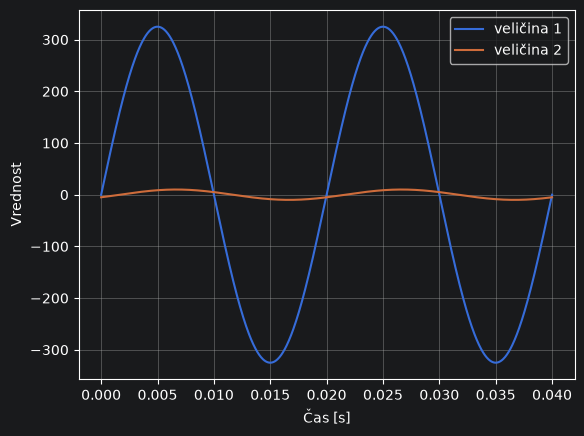

In [27]:
# REŠEN PRIMER:
primer_t = np.linspace(0, 0.04, 1000)
primer_y1 = 325 * np.sin(2*np.pi*50*primer_t)
primer_y2 = 10 * np.sin(2*np.pi*50*primer_t - np.deg2rad(30))

fig, ax1 = plt.subplots()
ax1.plot(primer_t, primer_y1, label="veličina 1")
ax1.plot(primer_t, primer_y2, label="veličina 2")
ax1.set_xlabel("Čas [s]")
ax1.set_ylabel("Vrednost")
ax1.grid(True)
ax1.legend()
plt.show()

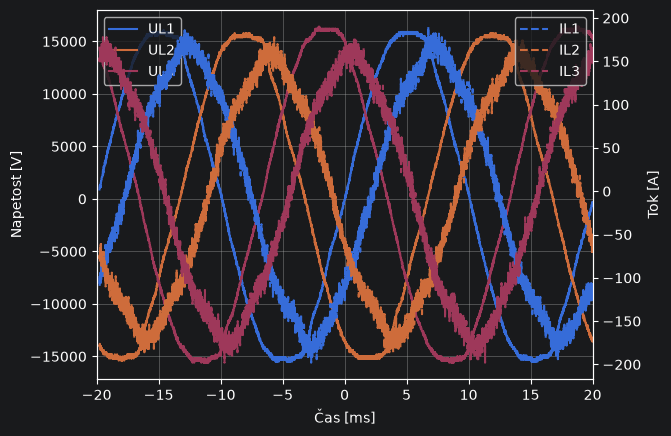

In [28]:
# VAŠA REŠITEV - Izrišite UL1, UL2, UL3 ter IL1, IL2, IL3.
t1 = read_col("Podatki/LV1_3xU_IL1.CSV", 0)   # čas meritve (-20 ... 20 ms)

fig, ax1 = plt.subplots()
ax1.plot(t1*1000, UL1, label="UL1")
ax1.plot(t1*1000, UL2, label="UL2")
ax1.plot(t1*1000, UL3, label="UL3")
ax1.set_xlabel("Čas [ms]")
ax1.set_ylabel("Napetost [V]")
ax1.set_xlim(-20, 20)
ax1.grid(True)
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.plot(t1*1000, IL1, "--", label="IL1")
ax2.plot(t1*1000, IL2, "--", label="IL2")
ax2.plot(t1*1000, IL3, "--", label="IL3")
ax2.set_ylabel("Tok [A]")
ax2.legend(loc="upper right")

plt.savefig("Rezultati/napetosti_in_tokovi.png")
plt.show()

## Naloga 2: Analiza spektra (FFT)
Naredite analizo frekvenčnega spektra za signale vseh treh napetosti in tokov. Za tem shranite vrednosti amplitud in faz za 50 Hz signal v spremenljivko `podatki_spekter` v DataFrame obliki. Struktura je že definirana v priloženi kodi, s katero si pomagajte in jo dopolnite.

### Primer: FFT sintetičnega signala
Primer vsebuje sinus pri 50 Hz, tretji harmonik pri 150 Hz in nekaj šuma.

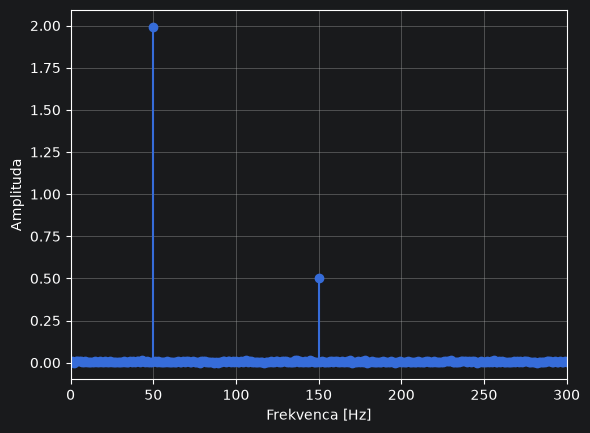

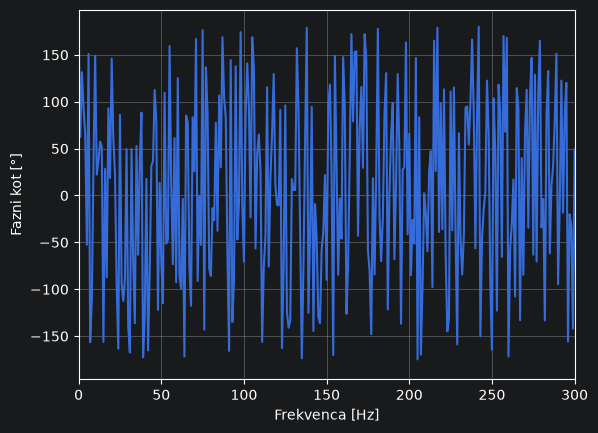

In [29]:
# REŠEN PRIMER:
primer_Fs = 2000                         # frekvenca vzorčenja [Hz]
primer_T = 1 / primer_Fs
primer_t_fft = np.arange(0, 1, primer_T)

rng = np.random.default_rng(1)
primer_signal = (2*np.sin(2*np.pi*50*primer_t_fft + np.deg2rad(20))
                  + 0.5*np.sin(2*np.pi*150*primer_t_fft)
                  + 0.15*rng.normal(size=len(primer_t_fft)))

primer_L = len(primer_signal)
primer_Y = np.fft.fft(primer_signal) / primer_L
primer_f = np.fft.fftfreq(primer_L, d=primer_T)

# Enostranski spekter
primer_mask = primer_f >= 0
primer_f_pos = primer_f[primer_mask]
primer_Y_pos = primer_Y[primer_mask]
primer_amplituda = 2*np.abs(primer_Y_pos)
primer_faza = np.angle(primer_Y_pos, deg=True)

fig, ax = plt.subplots()
ax.stem(primer_f_pos, primer_amplituda, basefmt=" ")
ax.set_xlim(0, 300)
ax.set_xlabel("Frekvenca [Hz]")
ax.set_ylabel("Amplituda")
ax.grid(True)
plt.show()

fig, ax = plt.subplots()
ax.plot(primer_f_pos, primer_faza)
ax.set_xlim(0, 300)
ax.set_xlabel("Frekvenca [Hz]")
ax.set_ylabel("Fazni kot [°]")
ax.grid(True)
plt.show()




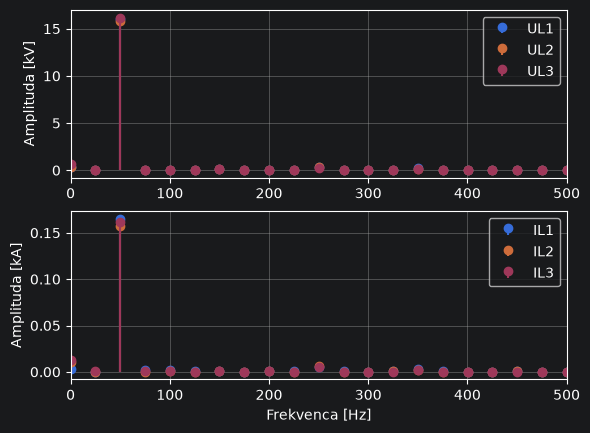

Amplituda in kot pri 50 Hz:
  Signal  Amplitude_kV   Phase_deg
0    UL1     16.011448  -86.359222
1    UL2     15.803479  153.042015
2    UL3     16.184922   33.804035
3    IL1      0.164739 -127.410551
4    IL2      0.157259  112.290349
5    IL3      0.161962   -5.173850


In [30]:
# VAŠA REŠITEV:
T = 7.68049e-6       # Sampling period [s] (Sample Interval iz glave CSV)
Fs = 1/T             # Sampling frequency [Hz]
L = len(UL1)         # Length of signal
t = np.arange(L)*T   # Time vector

# v signals vpišite napetosti in tokove za vse faze
signals = {"UL1": UL1, "UL2": UL2, "UL3": UL3, "IL1": IL1, "IL2": IL2, "IL3": IL3}
targetFreq = 50      # Ciljna frekvenca [Hz]

rows = []
fig, (axU, axI) = plt.subplots(2, 1)
for name, x in signals.items():
    # FFT analiza
    Y = np.fft.fft(x, n=L) / L
    f = Fs/2 * np.linspace(0, 1, L//2 + 1)

    amplitude = 2*np.abs(Y[:L//2+1]) / 1000            # [kV] ali [kA]
    angle_deg = np.degrees(np.arctan2(Y[:L//2+1].imag, Y[:L//2+1].real))

    # Poisce indeks najblizji 50 Hz
    idx = np.argmin(np.abs(f - targetFreq))

    rows.append({"Signal": name, "Amplitude_kV": amplitude[idx], "Phase_deg": angle_deg[idx]})

    # izris amplitudnega spektra
    if "U" in name:
        axU.stem(f, amplitude, linefmt=f"C{len(rows)-1}-", markerfmt=f"C{len(rows)-1}o", basefmt=" ", label=name)
    else:
        axI.stem(f, amplitude, linefmt=f"C{len(rows)-4}-", markerfmt=f"C{len(rows)-4}o", basefmt=" ", label=name)

axU.set_xlim(0, 500)
axI.set_xlim(0, 500)
axU.set_ylabel("Amplituda [kV]")
axI.set_ylabel("Amplituda [kA]")
axI.set_xlabel("Frekvenca [Hz]")
axU.grid(True)
axI.grid(True)
axU.legend()
axI.legend()
plt.show()

# zapis vrednosti v pd.DataFrame
podatki_spekter = pd.DataFrame(rows)
print("Amplituda in kot pri 50 Hz:")
print(podatki_spekter)

## Naloga 3: Kazalčni diagram
Vrednosti iz spremenljivke `podatki_spekter` uporabite za izris kazalčnega diagrama. Uporabite izračunane amplitude in kote napetosti in tokov za vse tri faze in sliko shranite v mapo `Rezultati` z imenom `kazalcni_diagram.png`. Tokovom skalirajte amplitudo s 100 povečavo in pomagajte si z že priloženo kodo.

### Primer: Izris kazalčnega diagrama

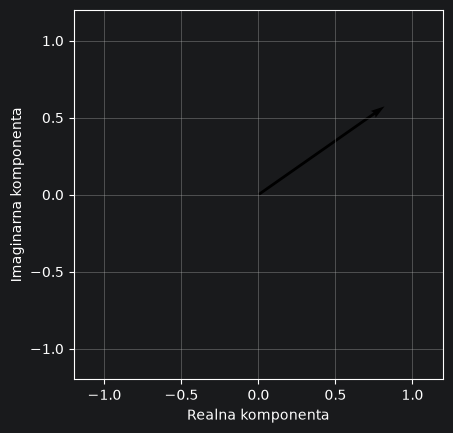

In [31]:
# REŠEN PRIMER:
primer_amp = 1.0
primer_phi_deg = 35
primer_phi_rad = np.deg2rad(primer_phi_deg)

primer_x = primer_amp * np.cos(primer_phi_rad)
primer_y = primer_amp * np.sin(primer_phi_rad)

fig, ax = plt.subplots()
ax.quiver(0, 0, primer_x, primer_y,
          angles="xy", scale_units="xy", scale=1)
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal")
ax.set_xlabel("Realna komponenta")
ax.set_ylabel("Imaginarna komponenta")
ax.grid(True)
plt.show()

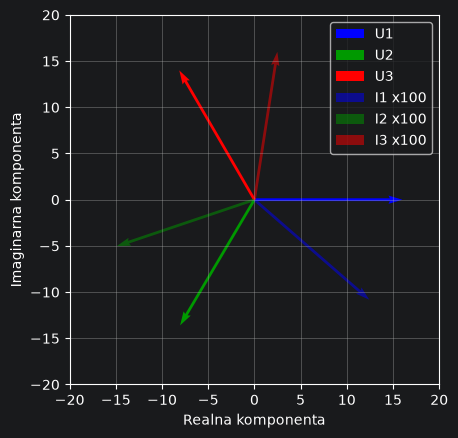

In [32]:
# VAŠA REŠITEV: uporabite spremenljivko podatki_spekter

# ločimo napetosti in tokove
U = podatki_spekter[podatki_spekter["Signal"].str.contains("UL")].reset_index(drop=True)
I = podatki_spekter[podatki_spekter["Signal"].str.contains("IL")].reset_index(drop=True)

# fazni koti relativno na U1 (v stopinjah), nato v radiane
fiU = np.deg2rad(U["Phase_deg"] - U["Phase_deg"][0])
fiI = np.deg2rad(I["Phase_deg"] - U["Phase_deg"][0])

barve = [(0, 0, 1), (0, 0.6, 0), (1, 0, 0)]   # modra, zelena, rdeca - faza 1,2,3

fig, ax = plt.subplots()

# --- Napetosti ---
for k in range(3):
    x = U["Amplitude_kV"][k] * np.cos(fiU[k])
    y = U["Amplitude_kV"][k] * np.sin(fiU[k])
    ax.quiver(0, 0, x, y, angles="xy", scale_units="xy", scale=1, color=barve[k], label=f"U{k+1}")

# --- Tokovi (skalirani x100) ---
for k in range(3):
    x = 100 * I["Amplitude_kV"][k] * np.cos(fiI[k])
    y = 100 * I["Amplitude_kV"][k] * np.sin(fiI[k])
    ax.quiver(0, 0, x, y, angles="xy", scale_units="xy", scale=1, color=barve[k], alpha=0.5, label=f"I{k+1} x100")

# Izris in shranjevanje kazalčnega diagrama
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_aspect("equal")
ax.set_xlabel("Realna komponenta")
ax.set_ylabel("Imaginarna komponenta")
ax.grid(True)
ax.legend()
plt.savefig("Rezultati/kazalcni_diagram.png")
plt.show()

## Naloga 4: Relativne temenske vrednosti in fazni koti osnovne komponente (H1)
Določite temenske vrednosti in fazne kote osnovne komponente relativno glede na napetost prve faze in vrednosti zapišite v spremenljivko `podatki_spekter_rel` v pd.DataFrame obliki (strukutra naj bo čisto ista kakor je spremenljivka `podatki_spekter`).

### Primer: Odčitavanje amplitude in faze pri 50 Hz

In [33]:
# REŠEN PRIMER: uporablja rezultat FFT iz prejšnjega demonstracijskega primera
primer_ciljna_f = 50
primer_idx = np.argmin(np.abs(primer_f_pos - primer_ciljna_f))

primer_A50 = primer_amplituda[primer_idx]
primer_phi50 = primer_faza[primer_idx]

print(f"Amplituda pri 50 Hz: {primer_A50:.3f}")
print(f"Fazni kot pri 50 Hz: {primer_phi50:.2f}°")

# Primer relativnega faznega kota
primer_phi_ref = 15.0
primer_phi_signal = -25.0
primer_phi_rel = primer_phi_signal - primer_phi_ref
print(f"Relativni fazni kot: {primer_phi_rel:.2f}°")

Amplituda pri 50 Hz: 1.993
Fazni kot pri 50 Hz: -70.04°
Relativni fazni kot: -40.00°


In [34]:
# VAŠA REŠITEV:
# Amplitude in absolutni koti ostanejo, dodamo stolpec Phase_rel = kot relativno na UL1 [°]
podatki_spekter_rel = podatki_spekter.copy()
podatki_spekter_rel["Phase_rel"] = podatki_spekter["Phase_deg"] - podatki_spekter["Phase_deg"][0]

print(podatki_spekter_rel)

  Signal  Amplitude_kV   Phase_deg   Phase_rel
0    UL1     16.011448  -86.359222    0.000000
1    UL2     15.803479  153.042015  239.401237
2    UL3     16.184922   33.804035  120.163256
3    IL1      0.164739 -127.410551  -41.051329
4    IL2      0.157259  112.290349  198.649571
5    IL3      0.161962   -5.173850   81.185372


## Naloga 5: Izris trenutnih faznih moči $p(t)$
Izračunajte trenutne moči $p_{1}(t)$, $p_{2}(t)$ in $p_{3}(t)$, kot produkt pripadajoče napetosti in toka. Nato poteke prikažite na enem grafu, ki ga shranite v mapo `Rezultati` z imenom `trenutne_moci.png`. Na časovni osi uporabite interval od **0 ms** do **40 ms**.


Izpeljava trenutne moči:
$$p_{L1}\left(t\right)=u_{L1}\left(t\right)\bullet i_{L1}\left(t\right)={\widehat{u}}_{L1}\bullet \cos{\left(\omega t+{\varphi }_{u}\right)\bullet {\widehat{i}}_{L1}\bullet \cos{\left(\omega t+{\varphi }_{i}\right)}}$$

$$p_{L1}\left(t\right)=\frac{1}{2}{\bullet \widehat{u}}_{L1}{\widehat{i}}_{L1}\bullet \left[\cos{\left({\varphi }_{u}-{\varphi }_{i}\right)+\cos{\left(2\omega t+{\varphi }_{u}+{\varphi }_{i}\right)}}\right]$$
### Primer: Trenutna moč enega para signalov

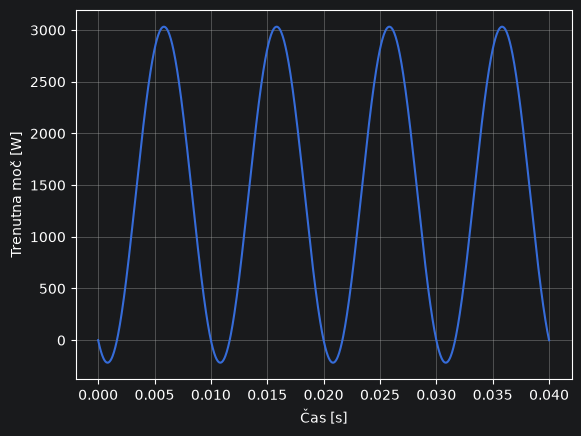

In [35]:
# REŠEN PRIMER:
primer_t_p = np.linspace(0, 0.04, 1000)
primer_u = 325*np.sin(2*np.pi*50*primer_t_p)
primer_i = 10*np.sin(2*np.pi*50*primer_t_p - np.deg2rad(30))
primer_p = primer_u * primer_i

fig, ax = plt.subplots()
ax.plot(primer_t_p, primer_p)
ax.set_xlabel("Čas [s]")
ax.set_ylabel("Trenutna moč [W]")
ax.grid(True)
plt.show()


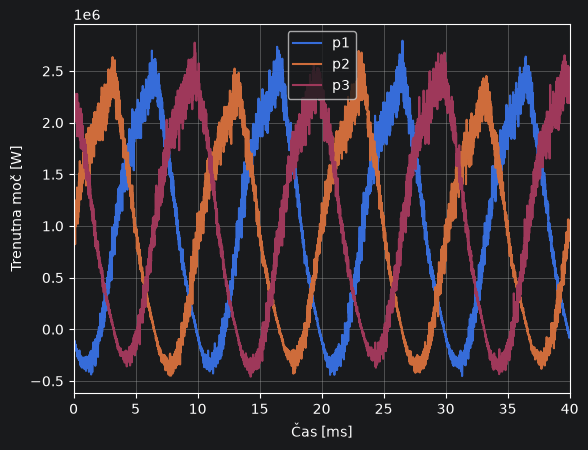

In [36]:
# VAŠA REŠITEV:
# Izračunajte p1 = UL1*IL1, p2 = UL2*IL2 in p3 = UL3*IL3
p1 = UL1 * IL1
p2 = UL2 * IL2
p3 = UL3 * IL3

fig, ax = plt.subplots()
ax.plot(t*1000, p1, label="p1")
ax.plot(t*1000, p2, label="p2")
ax.plot(t*1000, p3, label="p3")
ax.set_xlim(0, 40)
ax.set_xlabel("Čas [ms]")
ax.set_ylabel("Trenutna moč [W]")
ax.grid(True)
ax.legend()
plt.savefig("Rezultati/trenutne_moci.png")
plt.show()

## Naloga 6: Trenutna moč osnovne harmonske komponente
Izračunajte trenutne moči za vse tri faze, pri čemer določite aktivno, reaktivno in skupno moč za vsako fazo. Nato za prvo fazo izrišite vse tri moči (P, Q, S) na enem grafu in sliko shranite v mapo `Rezultati` z imenom `trenutna_moc_faza1.png`. Prav tako izrišite skupno moč (S) za vse tri faze na enem grafu in sliko shranite v mapo `Rezultati` z imenom `trenutna_moc_3f_skupaj.png`. Pri izrisu uporabite časovni interval od **0** do **50** ms. Pri reševanju uporabite spremenljivko `podatki_spekter` oziroma `U` in si pomagajte s priloženo kodo.

Enačbe za izračune:
$$
p_a(t) = \frac{1}{2} U I \cos(\varphi_U - \varphi_I)\left(1 + \cos(2\omega t + 2\varphi_U)\right)
$$

$$
p_r(t) = \frac{1}{2} U I \sin(\varphi_U - \varphi_I)\sin(2\omega t + 2\varphi_U)
$$

$$
p(t) = p_a(t) + p_r(t)
$$

### Primer: Analitična sestava $p(t)$ iz dveh prispevkov

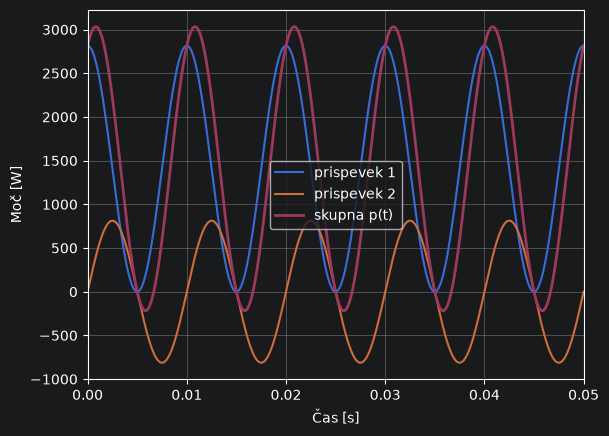

In [37]:
# REŠEN PRIMER:
primer_f = 50
primer_w = 2*np.pi*primer_f
primer_t_h1 = np.linspace(0, 0.05, 2000)
primer_Um = 325
primer_Im = 10
primer_phi_u = np.deg2rad(0)
primer_phi_i = np.deg2rad(-30)
primer_phi = primer_phi_u - primer_phi_i

primer_p_delovna = 0.5*primer_Um*primer_Im*np.cos(primer_phi) *     (1 + np.cos(2*primer_w*primer_t_h1 + 2*primer_phi_u))
primer_p_jalova = 0.5*primer_Um*primer_Im*np.sin(primer_phi) *     np.sin(2*primer_w*primer_t_h1 + 2*primer_phi_u)
primer_p_skupaj = primer_p_delovna + primer_p_jalova

fig, ax = plt.subplots()
ax.plot(primer_t_h1, primer_p_delovna, label="prispevek 1")
ax.plot(primer_t_h1, primer_p_jalova, label="prispevek 2")
ax.plot(primer_t_h1, primer_p_skupaj, label="skupna p(t)", linewidth=2)
ax.set_xlim(0, 0.05)
ax.set_xlabel("Čas [s]")
ax.set_ylabel("Moč [W]")
ax.grid(True)
ax.legend()
plt.show()


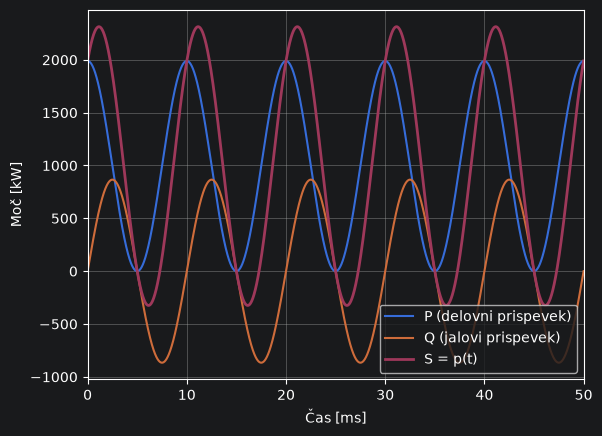

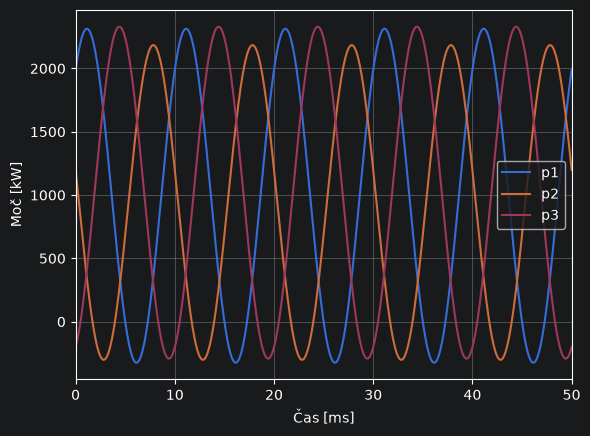

In [38]:
# VAŠA REŠITEV:
t = np.linspace(0, 0.05, 50001)   # 0:0.000001:0.05

# Napetosti:
ampU1 = U["Amplitude_kV"].iloc[0]   # kV
ampU2 = U["Amplitude_kV"].iloc[1]
ampU3 = U["Amplitude_kV"].iloc[2]

fiU1 = U["Phase_deg"].iloc[0] - U["Phase_deg"].iloc[0]      # relativno glede na napetost prve faze [stopinje]
fiU2 = U["Phase_deg"].iloc[1] - U["Phase_deg"].iloc[0]
fiU3 = U["Phase_deg"].iloc[2] - U["Phase_deg"].iloc[0]

# Tokovi: amplitude pomnožite z 1000
ampI1 = I["Amplitude_kV"].iloc[0] * 1000   # A
ampI2 = I["Amplitude_kV"].iloc[1] * 1000
ampI3 = I["Amplitude_kV"].iloc[2] * 1000

fiI1 = I["Phase_deg"].iloc[0] - U["Phase_deg"].iloc[0]
fiI2 = I["Phase_deg"].iloc[1] - U["Phase_deg"].iloc[0]
fiI3 = I["Phase_deg"].iloc[2] - U["Phase_deg"].iloc[0]

# Izračuni:  (kV * A = kW)
fu1, fu2, fu3 = np.deg2rad(fiU1), np.deg2rad(fiU2), np.deg2rad(fiU3)
fi1, fi2, fi3 = np.deg2rad(fiI1), np.deg2rad(fiI2), np.deg2rad(fiI3)

pa1 = 0.5*ampU1*ampI1*np.cos(fu1 - fi1) * (1 + np.cos(2*w*t + 2*fu1))
pr1 = 0.5*ampU1*ampI1*np.sin(fu1 - fi1) * np.sin(2*w*t + 2*fu1)
ps1 = pa1 + pr1

pa2 = 0.5*ampU2*ampI2*np.cos(fu2 - fi2) * (1 + np.cos(2*w*t + 2*fu2))
pr2 = 0.5*ampU2*ampI2*np.sin(fu2 - fi2) * np.sin(2*w*t + 2*fu2)
ps2 = pa2 + pr2

pa3 = 0.5*ampU3*ampI3*np.cos(fu3 - fi3) * (1 + np.cos(2*w*t + 2*fu3))
pr3 = 0.5*ampU3*ampI3*np.sin(fu3 - fi3) * np.sin(2*w*t + 2*fu3)
ps3 = pa3 + pr3

# Izris in shranjevanje za moč 1:
fig, ax = plt.subplots()
ax.plot(t*1000, pa1, label="P (delovni prispevek)")
ax.plot(t*1000, pr1, label="Q (jalovi prispevek)")
ax.plot(t*1000, ps1, label="S = p(t)", linewidth=2)
ax.set_xlim(0, 50)
ax.set_xlabel("Čas [ms]")
ax.set_ylabel("Moč [kW]")
ax.grid(True)
ax.legend()
plt.savefig("Rezultati/trenutna_moc_faza1.png")
plt.show()

# Izrisi in shranjevanje za vse moči skupaj:
fig, ax = plt.subplots()
ax.plot(t*1000, ps1, label="p1")
ax.plot(t*1000, ps2, label="p2")
ax.plot(t*1000, ps3, label="p3")
ax.set_xlim(0, 50)
ax.set_xlabel("Čas [ms]")
ax.set_ylabel("Moč [kW]")
ax.grid(True)
ax.legend()
plt.savefig("Rezultati/trenutna_moc_3f_skupaj.png")
plt.show()

## Naloga 7: Izračun $P$, $Q$ in $S$ za H1
Izračunajte delovne, jalove in navidezne moči za vsako fazo posebej in skupno. Rezultate shranite v spremenljivko `tabela` v dataFrame obliki s 4 stolpci in 4 vrsticami (podobno kot rešem primer samo, da zgoraj dodate vrstico: `"Faza": ["1", "2", "3", "Skupaj"]`. Pri tem uporabite spremenljivke: `P1`, `P2`, `P3`, `P` in enako za jalovo in navidezno moč.

Enačbe za pomoč pri izračunu (pozor - pazite ali uporabljate temenske ali efektivne vrednosti):
$$P_{L1}=U\bullet I\bullet \cos{\left({\varphi }_{u}-{\varphi }_{i}\right)}$$

$$Q_{L1}=U\bullet I\bullet \sin{({\varphi }_{u}-{\varphi }_{i})}$$

$$\left.\begin{matrix}P_{3f}=P_{L1}+P_{L2}+P_{L3} \\ Q_{3f}=Q_{L1}+Q_{L2}+Q_{L3}\end{matrix}\right\}\underline{S}=P_{3f}+jQ_{3f}$$

$$\cos{\varphi }=\frac{P_{3f}}{S_{3f}}$$

### Primer: Izračun moči ene faze in zapis v tabelo

,P [W],Q [var],S [VA]
0,1593.486743,920.0,1840.0


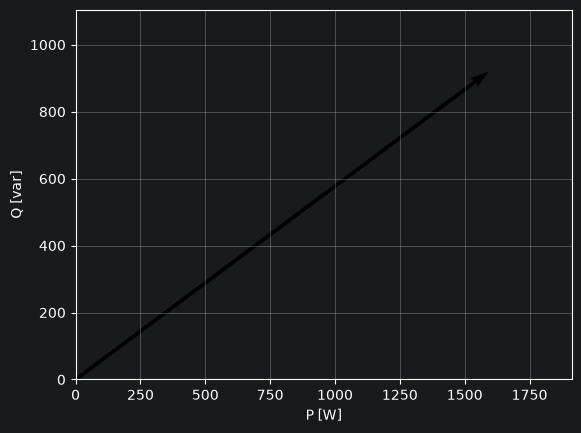

In [39]:
# REŠEN PRIMER:
primer_U_rms = 230
primer_I_rms = 8
primer_phi = np.deg2rad(30)

primer_P = primer_U_rms * primer_I_rms * np.cos(primer_phi)
primer_Q = primer_U_rms * primer_I_rms * np.sin(primer_phi)
primer_S = np.sqrt(primer_P**2 + primer_Q**2)

primer_tabela = pd.DataFrame({
    "P [W]": [primer_P],
    "Q [var]": [primer_Q],
    "S [VA]": [primer_S]
})
display(primer_tabela)

# Kazalec kompleksne moči S = P + jQ
fig, ax = plt.subplots()
ax.quiver(0, 0, primer_P, primer_Q,
          angles="xy", scale_units="xy", scale=1)
ax.set_xlim(0, 1.2*primer_P)
ax.set_ylim(0, 1.2*primer_Q)
ax.set_xlabel("P [W]")
ax.set_ylabel("Q [var]")
ax.grid(True)
plt.show()


In [40]:
# VAŠA REŠITEV - Izračunajte P, Q in S za vse tri faze ter njihove vsote.
# temenske vrednosti -> efektivne: U*I = (Û/√2)*(Î/√2) = Û*Î/2
# napetost v kV, tok v A -> kV * A = kW
P1 = 0.5*ampU1*ampI1*np.cos(fu1 - fi1)
P2 = 0.5*ampU2*ampI2*np.cos(fu2 - fi2)
P3 = 0.5*ampU3*ampI3*np.cos(fu3 - fi3)

Q1 = 0.5*ampU1*ampI1*np.sin(fu1 - fi1)
Q2 = 0.5*ampU2*ampI2*np.sin(fu2 - fi2)
Q3 = 0.5*ampU3*ampI3*np.sin(fu3 - fi3)

S1 = np.sqrt(P1**2 + Q1**2)
S2 = np.sqrt(P2**2 + Q2**2)
S3 = np.sqrt(P3**2 + Q3**2)

P = P1 + P2 + P3
Q = Q1 + Q2 + Q3
S = np.sqrt(P**2 + Q**2)

tabela = pd.DataFrame({
    "Faza": ["1", "2", "3", "Skupaj"],
    "P [kW]": [P1, P2, P3, P],
    "Q [kvar]": [Q1, Q2, Q3, Q],
    "S [kVA]": [S1, S2, S3, S]
})
display(tabela)

,Faza,P [kW],Q [kvar],S [kVA]
0,1,994.576877,866.138003,1318.854884
1,2,941.342397,811.160208,1242.620775
2,3,1018.902367,824.439898,1310.672797
3,Skupaj,2954.821641,2501.738110,3871.648809


## Naloga 8: Faktor delavnosti ($\cos\varphi$)
Določite faktor delavnosti osnovne komponente za celoten trifazni sistem in ga zapišite v spremenljivko `cosfi`.

### Primer: Izračun faktorja delavnosti

In [41]:
# REŠEN PRIMER:
primer_P = 1500
primer_S = 1800
primer_cosfi = primer_P / abs(primer_S)
print(f"cos(phi) = {primer_cosfi:.4f}")

# Enakovredno, če poznamo P in Q:
primer_Q = 900
primer_cosfi_2 = primer_P / np.sqrt(primer_P**2 + primer_Q**2)
print(f"cos(phi) iz P in Q = {primer_cosfi_2:.4f}")


cos(phi) = 0.8333
cos(phi) iz P in Q = 0.8575


In [42]:
# VAŠA REŠITEV - Faktor delavnosti določite iz skupnih P in S za vse tri faze.
cosfi = P / S
print(f"cos(phi) = {cosfi:.4f}")

cos(phi) = 0.7632


## Naloga 9: Shranjevanje rezultatov
Shrani naslednje spremenljivke v mapo `Rezultati` (CSV format):
- `tabela` → `tabela_moci.csv`
- `cosfi` → `cosfi_izracun.csv`
- `podatki_spekter` → `podatki_spekter_izracun.csv`
- `podatki_spekter_rel` → `podatki_spekter_rel_izracun.csv`

In [43]:
# VAŠA REŠITEV:
tabela.to_csv("Rezultati/tabela_moci.csv", index=False)
pd.DataFrame({"cosfi": [cosfi]}).to_csv("Rezultati/cosfi_izracun.csv", index=False)
podatki_spekter.to_csv("Rezultati/podatki_spekter_izracun.csv", index=False)
podatki_spekter_rel.to_csv("Rezultati/podatki_spekter_rel_izracun.csv", index=False)

## Naloga 10: Vprašanja
Odgovorite na spodnja vprašanja v naslednjo celico:
- Kakšen je karakter bremena in po čem/kako ga prepoznamo?
- Opiši vzročno-posledični odnos med harmonskim popačenjem toka bremena in napetosti na merilnem mestu. Kaj v največji meri prispeva k popačenju v omrežju?
- Ali lahko tudi višje harmonske komponente povzročajo delovno moč? Če da, kako/kdaj in če ne, zakaj?

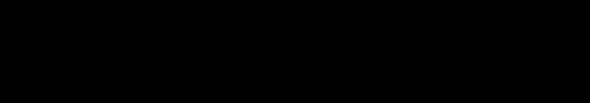
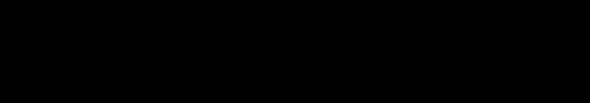

# Zapis rezultatov
Te celice **NE SPREMINJATI** samo na koncu jo poženite, da vidite ali ste rezultate zapisali pravilno. V kolikor vam ne javi napake --> ste pravilno zapisali spremenljivke. Pozor: to še ne pomeni, da imate izračune ali grafe pravilne.

In [45]:
spremenljivke = ['tabela', 'cosfi', 'podatki_spekter', 'podatki_spekter_rel']

vse_ok = True
for sprem in spremenljivke:
    if sprem in globals():
        print(f"✅ {sprem} - definirana")
    else:
        print(f"❌ {sprem} - NI definirana!")
        vse_ok = False

if vse_ok:
    print("\n✅ Vse spremenljivke so definirane!")
else:
    print("\n❌ Nekatere spremenljivke manjkajo!")

# 2. PREVERI MAPO IN DATOTEKE
print("\n2. PREVERJANJE MAPE 'Rezultati':")
print("-"*40)

if os.path.exists('Rezultati'):
    print("✅ Mapa 'Rezultati' obstaja")

    datoteke = ['cosfi_izracun.csv', 'tabela_moci.csv', 'podatki_spekter_izracun.csv', 'podatki_spekter_rel_izracun.csv', 'napetosti_in_tokovi.png', 'kazalcni_diagram.png','trenutne_moci.png', 'trenutna_moc_faza1.png', 'trenutna_moc_3f_skupaj.png']

    vse_datoteke_ok = True
    for dat in datoteke:
        pot = os.path.join('Rezultati', dat)
        if os.path.exists(pot):
            print(f"✅ {dat} - obstaja")
        else:
            print(f"❌ {dat} - NE OBSTAJA!")
            vse_datoteke_ok = False

    # Preveri dodatne datoteke
    vse_v_map = os.listdir('Rezultati')
    dodatne = [d for d in vse_v_map if d not in datoteke]
    if dodatne:
        print("\n⚠️ Dodatne datoteke v mapi (ki niso predvidene):")
        for d in dodatne:
            print(f"   {d}")

    if vse_datoteke_ok:
        print("\n✅ Vse datoteke so v mapi 'Rezultati'!")
    else:
        print("\n❌ Nekatere datoteke manjkajo!")

else:
    print("❌ Mapa 'Rezultati' NE OBSTAJA!")

✅ tabela - definirana
✅ cosfi - definirana
✅ podatki_spekter - definirana
✅ podatki_spekter_rel - definirana

✅ Vse spremenljivke so definirane!

2. PREVERJANJE MAPE 'Rezultati':
----------------------------------------
✅ Mapa 'Rezultati' obstaja
✅ cosfi_izracun.csv - obstaja
✅ tabela_moci.csv - obstaja
✅ podatki_spekter_izracun.csv - obstaja
✅ podatki_spekter_rel_izracun.csv - obstaja
✅ napetosti_in_tokovi.png - obstaja
✅ kazalcni_diagram.png - obstaja
✅ trenutne_moci.png - obstaja
✅ trenutna_moc_faza1.png - obstaja
✅ trenutna_moc_3f_skupaj.png - obstaja

✅ Vse datoteke so v mapi 'Rezultati'!


# Preverjanje rezultatov
Te celice **NE SPREMINJATI** samo na koncu jo poženite, da vidite ali so rezultati pravilni. V kolikor ste pravilno izračunali vse spremenljivke, boste prejeli token, ki ga vnesete v e-učilnico.

In [46]:
# ============================================================
# PREVERJANJE VAJE - TE CELICE NE SPREMINJAJTE
# Laboratorijska vaja 1 -> checker oznaka UV1
# ============================================================
# Za izdajo kode morajo biti pravilne spremenljivke:
#   podatki_spekter, podatki_spekter_rel, tabela, cosfi
#
# Grafi in datoteke so samo informativni in NE vplivajo na kodo.
# Zaradi omejitve pomnilnika na Renderju se grafi preverjajo
# zaporedoma: vsak PNG v svojem HTTP zahtevku.
# ============================================================

import base64
import json
import os
import time
import urllib.request
import urllib.error

CHECKER_URL = "https://fe-lab-checker.onrender.com/preveri"


def _za_json(vrednost):
    if vrednost is Ellipsis:
        return None
    if isinstance(vrednost, dict):
        return {str(k): _za_json(v) for k, v in vrednost.items()}
    if isinstance(vrednost, (list, tuple, set)):
        return [_za_json(v) for v in vrednost]

    if hasattr(vrednost, "to_dict"):
        try:
            return {
                "records": [
                    {str(k): _za_json(v) for k, v in row.items()}
                    for row in vrednost.to_dict(orient="records")
                ]
            }
        except Exception:
            try:
                return _za_json(vrednost.to_dict())
            except Exception:
                pass

    if hasattr(vrednost, "tolist"):
        try:
            return _za_json(vrednost.tolist())
        except Exception:
            pass

    if hasattr(vrednost, "item"):
        try:
            return _za_json(vrednost.item())
        except Exception:
            pass

    return vrednost


def _post(paket, timeout=150, retry=True):
    podatki = json.dumps(
        paket,
        ensure_ascii=False,
        allow_nan=False,
    ).encode("utf-8")

    zahteva = urllib.request.Request(
        CHECKER_URL,
        data=podatki,
        headers={"Content-Type": "application/json"},
        method="POST",
    )

    st_poskusov = 2 if retry else 1

    for poskus in range(st_poskusov):
        try:
            with urllib.request.urlopen(zahteva, timeout=timeout) as odgovor:
                return json.loads(odgovor.read().decode("utf-8")), None

        except urllib.error.HTTPError as e:
            # 502/503/504 se lahko pojavijo med prebujanjem ali restartom workerja.
            if e.code in (502, 503, 504) and poskus + 1 < st_poskusov:
                print(f"Checker je vrnil HTTP {e.code}; poskusam se enkrat ...")
                time.sleep(4)
                continue
            return None, f"HTTP {e.code}: {e.reason}"

        except (urllib.error.URLError, TimeoutError) as e:
            if poskus + 1 < st_poskusov:
                print("Checker se morda zaganja. Poskusam se enkrat ...")
                time.sleep(4)
                continue
            return None, str(e)

        except Exception as e:
            return None, str(e)

    return None, "neznana napaka"


def _slika_base64(ime):
    pot = os.path.join("Rezultati", ime)
    if not os.path.exists(pot):
        return None, "datoteka manjka"

    try:
        velikost = os.path.getsize(pot)
        if velikost > 4_000_000:
            return None, f"slika je prevelika ({velikost / 1_000_000:.1f} MB)"

        with open(pot, "rb") as f:
            return base64.b64encode(f.read()).decode("ascii"), None
    except Exception as e:
        return None, str(e)


def _izpisi_numericni_rezultat(rezultat):
    print("\n" + "=" * 52)
    print("                 REZULTAT PREVERJANJA")
    print("=" * 52)

    for kontrola in rezultat.get("checks", []):
        znak = "✅" if kontrola.get("ok") else "❌"
        print(f"{znak} {kontrola.get('name')}: {kontrola.get('message', '')}")

    print("-" * 52)
    print(f"Pravilno: {rezultat.get('passed', 0)} / {rezultat.get('total', 0)}")

    if rezultat.get("all_ok"):
        print("\n🎉 Vaja je uspesno opravljena!")
        print("\nKoda za eUcilnico:")
        print("=" * 52)
        print(rezultat.get("code", ""))
        print("=" * 52)
    else:
        print("\nPopravite oznacene rezultate in ponovno pozenite preverjanje.")


def _izpisi_oceno_grafa(rezultat, ime):
    for ocena in rezultat.get("advisory", []):
        if ocena.get("name") != ime:
            continue

        status = ocena.get("status")
        if status == "ok":
            znak = "✅"
        elif status == "likely_wrong":
            znak = "❌"
        else:
            znak = "⚠️"

        print(f"{znak} {ime}: {ocena.get('message', '')}")
        return

    print(f"⚠️ {ime}: streznik ni vrnil ocene grafa")


def preveri():
    zahtevane = [
        "podatki_spekter",
        "podatki_spekter_rel",
        "tabela",
        "cosfi",
    ]

    manjkajo = [x for x in zahtevane if x not in globals()]
    if manjkajo:
        print("❌ Najprej definirajte vse zahtevane spremenljivke:")
        for x in manjkajo:
            print(f"   - {x}")
        return

    if "vpisna_st" not in globals():
        print("❌ Manjka vpisna_st.")
        return

    try:
        vp = int(vpisna_st)
    except Exception:
        print("❌ vpisna_st mora biti veljavna stevilka.")
        return

    vrednosti = {x: _za_json(globals()[x]) for x in zahtevane}

    pricakovane_datoteke = [
        "cosfi_izracun.csv",
        "tabela_moci.csv",
        "podatki_spekter_izracun.csv",
        "podatki_spekter_rel_izracun.csv",
        "napetosti_in_tokovi.png",
        "kazalcni_diagram.png",
        "trenutne_moci.png",
        "trenutna_moc_faza1.png",
        "trenutna_moc_3f_skupaj.png",
    ]

    grafi = [
        "napetosti_in_tokovi.png",
        "kazalcni_diagram.png",
        "trenutne_moci.png",
        "trenutna_moc_faza1.png",
        "trenutna_moc_3f_skupaj.png",
    ]

    datoteke = {
        ime: os.path.exists(os.path.join("Rezultati", ime))
        for ime in pricakovane_datoteke
    }

    # 1) Najprej samo numerika. Tako grafi nikoli ne morejo preprečiti kode.
    osnovni_paket = {
        "vaja": "UV1",
        "vpisna_st": vp,
        "values": vrednosti,
        "files": datoteke,
        "images": {},
    }

    print("Preverjam numerične rezultate ...")
    rezultat, napaka = _post(osnovni_paket, timeout=150, retry=True)

    if napaka:
        print(f"❌ Checker trenutno ni dosegljiv: {napaka}")
        return

    if not isinstance(rezultat, dict):
        print("❌ Checker ni vrnil veljavnega odgovora.")
        return

    if rezultat.get("server_error"):
        print("⚠️ Napaka na checker strezniku:")
        print(rezultat["server_error"])
        return

    _izpisi_numericni_rezultat(rezultat)

    # 2) Nato informativno preverimo vsak graf posebej.
    print("\n" + "=" * 52)
    print("            GRAFI - INFORMATIVNO")
    print("            (NE vplivajo na kodo)")
    print("=" * 52)

    for i, ime in enumerate(grafi, start=1):
        slika, napaka_slike = _slika_base64(ime)
        if slika is None:
            print(f"⚠️ {ime}: {napaka_slike}")
            continue

        print(f"[{i}/{len(grafi)}] Preverjam {ime} ...")

        paket_graf = {
            "vaja": "UV1",
            "vpisna_st": vp,
            "values": vrednosti,
            "files": datoteke,
            "images": {ime: slika},
        }

        rez_graf, napaka_grafa = _post(paket_graf, timeout=120, retry=True)

        if napaka_grafa:
            print(f"⚠️ {ime}: slikovno preverjanje ni uspelo ({napaka_grafa})")
            print("   Numerični rezultat in koda ostaneta veljavna.")
            continue

        if isinstance(rez_graf, dict) and rez_graf.get("server_error"):
            print(f"⚠️ {ime}: {rez_graf['server_error']}")
            continue

        if not isinstance(rez_graf, dict):
            print(f"⚠️ {ime}: neveljaven odgovor slikovnega checkerja")
            continue

        _izpisi_oceno_grafa(rez_graf, ime)

        # Kratek premor, da lahko worker sprosti pomnilnik pred naslednjim grafom.
        time.sleep(1)


preveri()


Preverjam numerične rezultate ...

                 REZULTAT PREVERJANJA
✅ podatki_spekter: vrednosti amplitud in faz so pravilne
✅ podatki_spekter_rel: vrednosti amplitud in faz so pravilne
✅ tabela: P, Q in S so pravilni za vse tri faze in skupaj
✅ cosfi: pravilno
----------------------------------------------------
Pravilno: 4 / 4

🎉 Vaja je uspesno opravljena!

Koda za eUcilnico:
PM8DR9KLVY2R

            GRAFI - INFORMATIVNO
            (NE vplivajo na kodo)
[1/5] Preverjam napetosti_in_tokovi.png ...
⚠️ napetosti_in_tokovi.png: najbrz je pravilno, vendar preverite graf (podobnost 87.3%, ujemanje oblike 0.77)
[2/5] Preverjam kazalcni_diagram.png ...
❌ kazalcni_diagram.png: najbrz je nekaj narobe z grafom (podobnost 89.1%, ujemanje oblike 0.28)
[3/5] Preverjam trenutne_moci.png ...
❌ trenutne_moci.png: najbrz je nekaj narobe z grafom (podobnost 86.3%, ujemanje oblike 0.70)
[4/5] Preverjam trenutna_moc_faza1.png ...
❌ trenutna_moc_faza1.png: najbrz je nekaj narobe z grafom (podobnos

In [47]:
# ============================================================
# ZAČASNI TEST 3 - katero enoto za tabela sprejme checker (rel je zdaj pravilen)
# ============================================================
import json
def poskusi_tab(tab):
    vr = {"podatki_spekter": _za_json(podatki_spekter), "podatki_spekter_rel": _za_json(podatki_spekter_rel),
          "tabela": _za_json(tab), "cosfi": _za_json(cosfi)}
    paket = {"vaja": "UV1", "vpisna_st": int(vpisna_st), "values": vr, "files": {}, "images": {}}
    return _post(paket, timeout=150, retry=True)

print("TEST ENOT ZA TABELA:")
for ime, k in [("MW (zdaj)", 1), ("kW", 1e3), ("W", 1e6), ("MW x2", 2), ("kW x2", 2e3),
               ("kW /2", 500), ("kW x√2", 1e3*np.sqrt(2)), ("kW x√3", 1e3*np.sqrt(3))]:
    t_ = tabela.copy()
    for c in ["P [kW]", "Q [kvar]", "S [kVA]"]:
        t_[c] = tabela[c] * k
    rez, nap = poskusi_tab(t_)
    if nap:
        print(f"{ime:12s} NAPAKA {nap}"); continue
    tab_ch = [c for c in rez.get("checks", []) if c["name"] == "tabela"][0]
    print(f"{ime:12s} {tab_ch['ok']}  {tab_ch.get('message','')}   (skupaj {rez.get('passed')}/{rez.get('total')})")


TEST ENOT ZA TABELA:
MW (zdaj)    True  P, Q in S so pravilni za vse tri faze in skupaj   (skupaj 4/4)
kW           False  napacna vrednost P [kW] za vrstico 1   (skupaj 3/4)
W            False  napacna vrednost P [kW] za vrstico 1   (skupaj 3/4)
MW x2        False  napacna vrednost P [kW] za vrstico 1   (skupaj 3/4)
kW x2        False  napacna vrednost P [kW] za vrstico 1   (skupaj 3/4)
kW /2        False  napacna vrednost P [kW] za vrstico 1   (skupaj 3/4)
kW x√2       False  napacna vrednost P [kW] za vrstico 1   (skupaj 3/4)
kW x√3       False  napacna vrednost P [kW] za vrstico 1   (skupaj 3/4)
